# 02 · GAN training dynamics: equilibrium, instability, mode collapse
### The Class 2 & 3 notebook (GAN-Class-2-3-Training-Dynamics.ipynb), rebuilt and run

**Covers (GAN Class 2 & 3 slides):** Nash equilibrium and why gradient play circles it · instability · mode collapse and mode hopping · five popular fixes, tested · diagnosing a real MNIST GAN with D(x) / D(G(z)) plots, fixed-noise grids and a digit histogram.

**Where the code comes from.** The course guide *"GAN Class 2 & 3 Notebook Explained"* describes this notebook part by part, with its function names (`play_game`, `sample_real`, `Generator2D`, `Discriminator2D`, `mode_coverage`, `train_ring_gan`, `show_snapshots`, `digit_histogram`, `train_mnist_gan`), defaults and experiments. This notebook follows it exactly. The guide quotes the results of the course's own test run; **your numbers here come from this run** and are compared with the guide's honestly where they differ (GANs are sensitive to seeds and hardware; compare patterns, not exact numbers).

> **The key fact:** a GAN is a **game**, not a single optimisation. A classifier chases a target that stays still. In a GAN, G's target is D's opinion, and D is learning too. Like hiking down a valley while someone keeps reshaping the ground.

| Part | What you do | Links to theory |
|---|---|---|
| 0 | imports and seeds | |
| 1 | play the x·y game; watch the players circle the equilibrium | Nash equilibrium |
| 2 | 8-cluster ring data, the two networks, a coverage measure | what a mode is |
| 3 | train a GAN on the ring and watch it collapse and hop | mode collapse |
| 4 | test five fixes and fill in a results table | the toolbox |
| 5 | the Class 1 MNIST GAN twice, with diagnostic plots | instability |
| 6 | reflection questions with model answers | all |

Cells marked **✏️ Predict** ask for a guess *before* you run the next cell. Write the guess first; the answer is revealed after the run.

### Words you need

| Term | Plain meaning |
|---|---|
| **Game / zero-sum game** | each player's best choice depends on the other's; in zero-sum, one's gain is exactly the other's loss (a GAN's minimax objective is one) |
| **Nash equilibrium** | choices where no player can do better by changing **only its own** choice |
| **Gradient descent / ascent** | moving a number in the direction that makes a value smaller / larger |
| **Mode** | a peak of the data: one "kind" of sample (one cluster, one digit) |
| **Mode collapse / hopping** | G produces only one or a few modes / the collapsed output jumps between modes during training |
| **Logit** | a raw score before the sigmoid squashes it into 0–1 |
| **Label smoothing** | training D with target 0.9 for real images instead of 1.0 |
| **Instance noise** | adding a little random noise to the images D sees |
| **TTUR** | two time-scale update rule: D and G get different learning rates |
| **Minibatch std** | giving D one extra number: how spread out the whole batch is |
| **Adam β1** | how much of its previous direction Adam keeps (its momentum) |
| **Seed** | the starting number for random choices; same seed → same run |

## Part 0 · Setup

In [1]:
%matplotlib inline
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams["figure.dpi"] = 80
print("torch", torch.__version__, "| GPU available:", torch.cuda.is_available())

torch 2.14.1+cu130 | GPU available: False


## Part 1 · The smallest possible game: V(x, y) = x · y

A real GAN has hundreds of thousands of weights. To *see* the behaviour, shrink the game to two numbers:
- **Player x** wants V = x·y **small** (it plays G's role);
- **Player y** wants V = x·y **large** (it plays D's role).

**Where is the equilibrium?** At **(0, 0)**. If y = 0, V = 0 whatever x does, so x has nothing to gain by moving; if x = 0, the same holds for y. Neither player regrets its choice: a Nash equilibrium.

**Gradient play.** The slope of x·y with respect to x is y, and with respect to y is x. So each step is
```
x = x - lr * y   # x walks downhill on V (gradient descent)
y = y + lr * x   # y walks uphill on V (gradient ascent)
```
`play_game` runs 200 of these steps from **(1, 1)** with **lr = 0.1**, in two ways:
- **simultaneous:** both players use the *old* values: `x, y = x - lr * y, y + lr * x`;
- **alternating:** x moves first, then y reacts to the *new* x. This matches our GAN code (D steps, then G steps).

In [2]:
def play_game(steps=200, lr=0.1, simultaneous=True, start=(1.0, 1.0)):
    x, y = start
    path = [(x, y)]
    for _ in range(steps):
        if simultaneous:
            x, y = x - lr * y, y + lr * x      # both use the old values
        else:
            x = x - lr * y                     # x moves first...
            y = y + lr * x                     # ...then y reacts to the NEW x
        path.append((x, y))
    return np.array(path)

> ✏️ **Predict:** after 200 steps, which version ends closer to the equilibrium (0, 0)? Will either of them reach it? (Start distance = √2 ≈ 1.41.)

start distance from (0, 0): 1.41
simultaneous: distance after 200 steps = 3.83
alternating : distance after 200 steps = 1.36


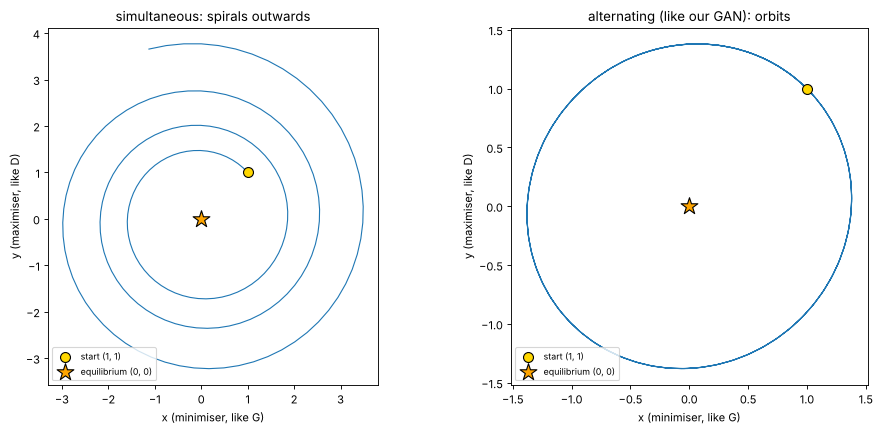

In [3]:
sim = play_game(simultaneous=True)
alt = play_game(simultaneous=False)
print(f"start distance from (0, 0): {math.hypot(1, 1):.2f}")
print(f"simultaneous: distance after 200 steps = {np.hypot(*sim[-1]):.2f}")
print(f"alternating : distance after 200 steps = {np.hypot(*alt[-1]):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, path, title in [(ax[0], sim, "simultaneous: spirals outwards"), (ax[1], alt, "alternating (like our GAN): orbits")]:
    a.plot(path[:, 0], path[:, 1], lw=1)
    a.scatter(*path[0], c="gold", s=80, zorder=3, edgecolor="k", label="start (1, 1)")
    a.scatter(0, 0, marker="*", c="orange", s=250, zorder=3, edgecolor="k", label="equilibrium (0, 0)")
    a.set_aspect("equal"); a.set_title(title); a.set_xlabel("x (minimiser, like G)"); a.set_ylabel("y (maximiser, like D)"); a.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Answer revealed.** **Neither** reaches the equilibrium. **Simultaneous** updates spiral **outwards**: the distance grows from 1.41 to **3.83**. **Alternating** updates go round and round on a closed loop: the distance after 200 steps is **1.36**, about where it started. These are exactly the guide's numbers (about 3.83 and about 1.36): this part involves no randomness, so every machine gets the same result.

**Why does it circle?** The arrow plot below draws, at every point, the direction one step of gradient play pushes (x, y). Each player's step depends on the **other** player's position:

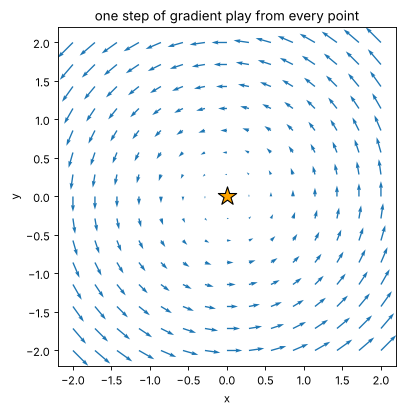

In [4]:
xs, ys = np.meshgrid(np.linspace(-2, 2, 15), np.linspace(-2, 2, 15))
u, v = -ys, xs                           # x moves by -y (descent), y moves by +x (ascent)
plt.figure(figsize=(5.5, 5.5))
plt.quiver(xs, ys, u, v, color="tab:blue")
plt.scatter(0, 0, marker="*", c="orange", s=300, edgecolor="k", zorder=3)
plt.gca().set_aspect("equal"); plt.title("one step of gradient play from every point"); plt.xlabel("x"); plt.ylabel("y")
plt.show()

The arrows go **around** (0, 0), never towards it. Follow the quadrants: at x > 0, y > 0, x moves left and y moves up; at x < 0, y > 0, x moves left and y down; ... a rotation. Nobody's step aims at the equilibrium.

With simultaneous updates the distance is multiplied by **√(1 + lr²)** at every step (for lr = 0.1, 200 steps: √2 · 1.01^100 ≈ 3.83), so it grows for ever. Alternating updates cancel that growth exactly, so the path stays on a closed loop.

### Exercise 1 · Does a smaller learning rate fix it?
> ✏️ **Predict:** with lr = 0.01, will the players reach (0, 0)?

In [5]:
print("simultaneous updates, 200 steps:")
for lr in [0.01, 0.1, 0.5]:
    d = np.hypot(*play_game(lr=lr)[-1])
    print(f"  lr = {lr:<4}: distance = {d:,.3f}   (formula sqrt(2) * (1 + lr^2)^100 = {math.sqrt(2) * (1 + lr**2) ** 100:,.3f})")
print("alternating updates, 2,000 steps (min / max distance along the path):")
for lr in [0.01, 0.1, 0.5]:
    d = np.hypot(*play_game(steps=2000, lr=lr, simultaneous=False).T)
    print(f"  lr = {lr:<4}: final {d[-1]:.3f}, min {d.min():.3f}, max {d.max():.3f}")

simultaneous updates, 200 steps:
  lr = 0.01: distance = 1.428   (formula sqrt(2) * (1 + lr^2)^100 = 1.428)
  lr = 0.1 : distance = 3.825   (formula sqrt(2) * (1 + lr^2)^100 = 3.825)
  lr = 0.5 : distance = 6,942,506,557.581   (formula sqrt(2) * (1 + lr^2)^100 = 6,942,506,557.581)
alternating updates, 2,000 steps (min / max distance along the path):
  lr = 0.01: final 1.408, min 1.407, max 1.414
  lr = 0.1 : final 1.367, min 1.345, max 1.414
  lr = 0.5 : final 1.237, min 1.095, max 1.414


**Answer revealed.** No. With simultaneous updates the distance after 200 steps is **1.428** for lr = 0.01 (spirals out very slowly), **3.825** for lr = 0.1 and about **6.9 billion** for lr = 0.5 (explodes), matching the guide's 1.428 / 3.825 / ≈ 6.9 billion and the √(1 + lr²) formula exactly. With alternating updates and 2,000 steps the distance stays between about 1.1 and 1.41 for every learning rate: the players keep orbiting and **never** approach (0, 0). A smaller learning rate only slows the spiral; it does not point the players at the equilibrium.

**One sentence:** two players each descending **their own** loss is not the same as minimising **one** loss, because each player's gradient depends on the other player's position; the combined motion rotates. Real GAN fixes therefore change the game or the optimiser, not just the step size.

## Part 2 · A GAN you can see: 8 clusters on a ring
MNIST images have 784 numbers each, so you can't see the whole data distribution. Here each sample is just a **point (x, y)**.

In [6]:
MODES = torch.tensor([[2 * math.cos(2 * math.pi * i / 8), 2 * math.sin(2 * math.pi * i / 8)] for i in range(8)])

def sample_real(n, std=0.02):
    idx = torch.randint(0, 8, (n,))
    return MODES[idx] + std * torch.randn(n, 2)

- `MODES` holds **8 centre points** evenly spaced on a circle of radius 2.
- `sample_real(n)` picks a random centre for each of the n points and adds a tiny bit of noise (`std=0.02`): **8 tight clusters**. Each cluster is **one mode**; a good generator must put points in all 8.

### The two networks

In [7]:
class Generator2D(nn.Module):
    def __init__(self, z_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 2))                  # a point (x, y)
    def forward(self, z):
        return self.net(z)


class Discriminator2D(nn.Module):
    def __init__(self, mbstd=False):
        super().__init__()
        self.mbstd = mbstd
        self.net = nn.Sequential(
            nn.Linear(2 + int(mbstd), 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 128), nn.LeakyReLU(0.2),
            nn.Linear(128, 1))                  # a raw score (logit): no Sigmoid
    def forward(self, x):
        if self.mbstd:
            # minibatch standard deviation: how spread out is the WHOLE batch?
            spread = x.std(dim=0).mean()                        # one number for the batch
            x = torch.cat([x, spread.expand(x.size(0), 1)], 1)  # copied to every point as a 3rd input
        return self.net(x)

bce = nn.BCEWithLogitsLoss()

- **Generator2D:** a noise vector (256 numbers by default) → two hidden layers of 128 with ReLU → 2 numbers, a point.
- **Discriminator2D:** a point → LeakyReLU hidden layers → **one raw score (a logit)**. There is **no Sigmoid** at the end because we use **`nn.BCEWithLogitsLoss`**, which applies the sigmoid *inside* the loss. Same maths as Class 1's Sigmoid + `BCELoss`, just more numerically stable.
- **`mbstd=True`** adds **minibatch standard deviation**: D gets one extra input, the average spread of the whole batch, copied to every point. A batch where all points sit in one place has a tiny spread, so D can notice **missing variety**. Used in Part 4.

### Measuring variety: `mode_coverage`
Returns two numbers for a set of points:
- **modes covered (0–8):** how many clusters receive **at least 2%** of the points, where a point counts for a cluster when it is **within 0.3** of that cluster's centre;
- **quality (0–1):** the fraction of points that land near **any** cluster.

real data: modes covered = 8 / 8, quality = 1.00
a 'collapsed' set, all near cluster 0: modes covered = 1 / 8, quality = 1.00


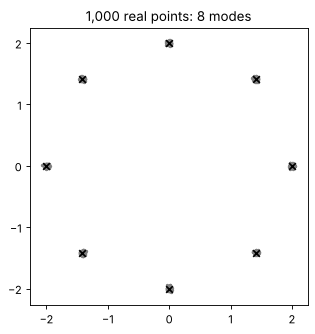

In [8]:
def mode_coverage(points, radius=0.3, min_share=0.02):
    dist = torch.cdist(points, MODES)            # distance from every point to every centre
    nearest_d, nearest = dist.min(dim=1)
    near = nearest_d < radius
    share = torch.bincount(nearest[near], minlength=8).float() / len(points)
    modes = int((share >= min_share).sum())
    quality = near.float().mean().item()
    return modes, quality

real_pts = sample_real(1000)
print("real data: modes covered = %d / 8, quality = %.2f" % mode_coverage(real_pts))
one_blob = MODES[0] + 0.02 * torch.randn(1000, 2)
print("a 'collapsed' set, all near cluster 0: modes covered = %d / 8, quality = %.2f" % mode_coverage(one_blob))

plt.figure(figsize=(4.5, 4.5))
plt.scatter(*real_pts.T, s=4, c="grey"); plt.scatter(*MODES.T, marker="x", c="k")
plt.gca().set_aspect("equal"); plt.title("1,000 real points: 8 modes"); plt.show()

Real data scores **(8, 1.00)**. A collapsed generator can score **high quality but only 1 mode**: every point looks real, but they are all in the same place. That is why we need *both* numbers.

## Part 3 · Train the baseline and watch it collapse
`train_ring_gan(...)` is the Class 1 loop with switches added for the experiments. Its defaults are the **baseline**: `z_dim=256`, `lr_g=lr_d=1e-4`, Adam `betas=(0.5, 0.999)`, batches of 256 points, **4,000 steps**, `seed=0`.

In [9]:
def train_ring_gan(z_dim=256, lr_g=1e-4, lr_d=1e-4, betas=(0.5, 0.999), batch=256, steps=4000, seed=0,
                   real_label=1.0, instance_noise=0.0, mbstd=False, snapshot_every=500):
    torch.manual_seed(seed)
    G, D = Generator2D(z_dim), Discriminator2D(mbstd)
    opt_g = optim.Adam(G.parameters(), lr=lr_g, betas=betas)
    opt_d = optim.Adam(D.parameters(), lr=lr_d, betas=betas)
    fixed_z = torch.randn(1000, z_dim)           # reused for every snapshot
    losses, snapshots = [], []
    for step in range(1, steps + 1):
        # Step 1: train D (G frozen by .detach())
        real = sample_real(batch)
        fake = G(torch.randn(batch, z_dim)).detach()
        if instance_noise > 0:                   # blur both piles before D sees them
            real = real + instance_noise * torch.randn_like(real)
            fake = fake + instance_noise * torch.randn_like(fake)
        loss_d = bce(D(real), torch.full((batch, 1), real_label)) + bce(D(fake), torch.zeros(batch, 1))
        opt_d.zero_grad(); loss_d.backward(); opt_d.step()
        # Step 2: train G (fresh fakes, no detach)
        fake = G(torch.randn(batch, z_dim))
        loss_g = bce(D(fake), torch.ones(batch, 1))  # non-saturating loss from Class 1
        opt_g.zero_grad(); loss_g.backward(); opt_g.step()
        losses.append((loss_d.item(), loss_g.item()))
        if step % snapshot_every == 0:
            with torch.no_grad():
                pts = G(fixed_z)
            snapshots.append((step, pts, *mode_coverage(pts)))
    return G, np.array(losses), snapshots


def show_snapshots(snapshots, title=""):
    fig, axes = plt.subplots(1, len(snapshots), figsize=(2.1 * len(snapshots), 2.4))
    ref = sample_real(1000)
    for a, (step, pts, modes, quality) in zip(axes, snapshots):
        a.scatter(*ref.T, s=1, c="lightgrey"); a.scatter(*pts.T, s=1, c="tab:blue")
        a.set_xlim(-3, 3); a.set_ylim(-3, 3); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
        a.set_title(f"step {step}\n{modes}/8 modes", fontsize=9)
    plt.suptitle(title, y=1.04); plt.tight_layout(); plt.show()


def show_curves(losses, snapshots, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
    k = 50
    for i, name in enumerate(["loss D", "loss G"]):
        ax[0].plot(np.convolve(losses[:, i], np.ones(k) / k, mode="valid"), label=name)
    ax[0].set_xlabel("step"); ax[0].set_title("losses (smoothed over 50 steps)"); ax[0].legend()
    ax[1].plot([s[0] for s in snapshots], [s[2] for s in snapshots], "o-")
    ax[1].set_ylim(-0.3, 8.3); ax[1].set_xlabel("step"); ax[1].set_title("modes covered (of 8)")
    plt.suptitle(title, y=1.03); plt.tight_layout(); plt.show()

| Code | What it does |
|---|---|
| `torch.manual_seed(seed)` | makes the run repeatable |
| `fixed_z = torch.randn(1000, z_dim)` | 1,000 noise vectors reused for every snapshot, so pictures are comparable over time |
| Step 1: `real = sample_real(batch)`, `fake = G(...).detach()` | one pile of real points, one of fakes; `.detach()` keeps G frozen |
| `if instance_noise > 0: ...` | optional: blur both piles with random noise before D sees them |
| `loss_d = bce(D(real), real_label) + bce(D(fake), 0)` | D's loss; `real_label` is 1.0 normally, 0.9 with label smoothing |
| Step 2: `fake = G(torch.randn(...))` | fresh fakes, **without** detach, so gradients flow into G |
| `loss_g = bce(D(fake), 1)` | the non-saturating generator loss from Class 1 |
| `if step % snapshot_every == 0` | every 500 steps, draw the 1,000 fixed-noise points and record their coverage |

> ✏️ **Predict:** after 4,000 steps, how many of the 8 clusters will the generator cover? Will the loss curves warn you if something is wrong?

baseline trained in 25 s
modes covered at each snapshot: [1, 1, 1, 1, 0, 1, 1, 1]
quality at each snapshot     : [0.07, 0.25, 0.23, 0.18, 0.01, 0.03, 0.27, 0.07]
blob centre at each snapshot  : [(-0.5, 2.2), (1.7, -0.0), (-0.2, -2.1), (-2.0, -0.3), (-0.6, 1.9), (1.5, 0.9), (1.5, -1.3), (-0.4, -1.9)]


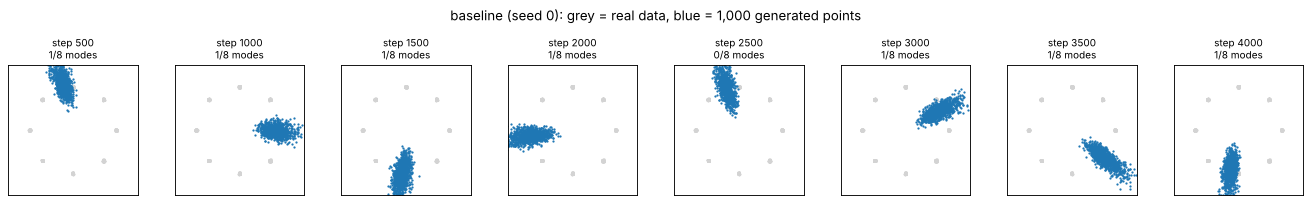

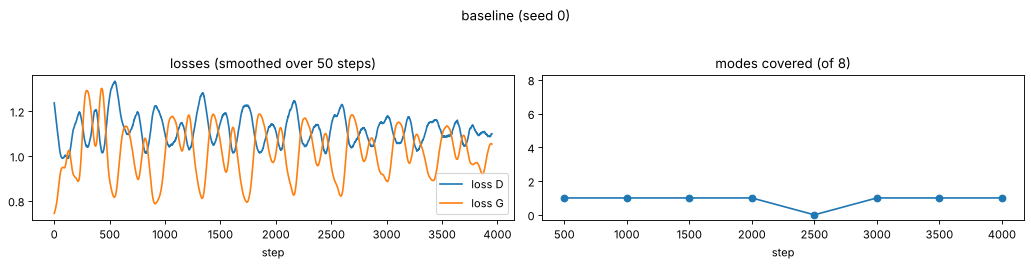

In [10]:
t0 = time.time()
G_base, losses_base, snaps_base = train_ring_gan()
print(f"baseline trained in {time.time() - t0:.0f} s")
print("modes covered at each snapshot:", [s[2] for s in snaps_base])
print("quality at each snapshot     :", [round(s[3], 2) for s in snaps_base])
print("blob centre at each snapshot  :", [tuple(round(float(v), 1) for v in s[1].mean(0)) for s in snaps_base])
show_snapshots(snaps_base, "baseline (seed 0): grey = real data, blue = 1,000 generated points")
show_curves(losses_base, snaps_base, "baseline (seed 0)")

**Answer revealed.** At **every** snapshot the 1,000 blue points form **one blob**, covering at most **1 of 8** clusters (0 of 8 at step 2,500, when the blob sat between clusters). A thousand different noise vectors are mapped to almost the same place: **mode collapse**. And the blob **moves** between snapshots: top, right, bottom, left, top again, then right, bottom-right, bottom (see the printed blob centres): **mode hopping**. Meanwhile the loss plot wobbles in a regular rhythm between about 0.8 and 1.3 and says nothing about the 7 missing clusters. **Losses do not measure variety.**

This matches the guide's description of its own seed-0 run (one blob, at most 1 of 8, hopping, losses between about 0.8 and 1.4). One small difference: in our run the blob is fairly wide and often sits just beside a cluster rather than on it, so its quality score is low (0.01–0.27); the guide describes a tight blob.

**Why does this happen?**
- **D judges one point at a time.** A point in (or near) a real cluster looks real on its own. D never sees that *all* the points are in the same place, so it cannot punish missing variety.
- **G only follows today's D.** Its gradient says "move towards what D likes right now". The quickest way to lower its loss is to send every noise vector to D's current favourite spot.
- **Hopping is the chase from Part 1.** G settles on a spot; D learns that points there are fake; G's gradient pushes it somewhere D still likes; D follows. The rhythmic wobble in the loss plot is this chase.

The original GAN paper warned about exactly this, calling it the **"Helvetica scenario"**: G collapses too many values of z to the same output.

### Exercise 2 · Same settings, different seed

seed 1, modes covered at each snapshot: [0, 1, 1, 1, 1, 1, 0, 1]


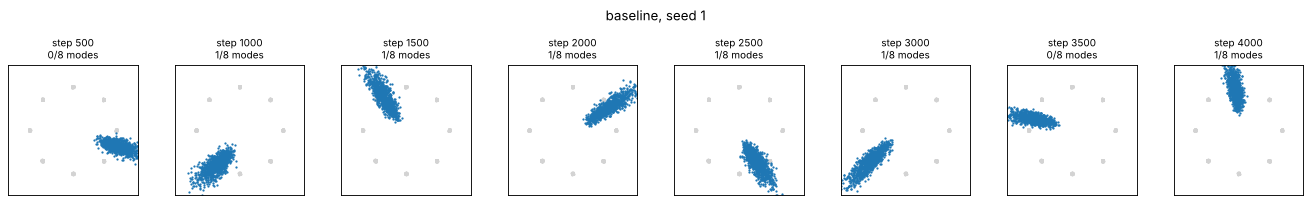

In [11]:
G_s1, losses_s1, snaps_s1 = train_ring_gan(seed=1)
print("seed 1, modes covered at each snapshot:", [s[2] for s in snaps_s1])
show_snapshots(snaps_s1, "baseline, seed 1")

**Exercise 2 answers (from this run).**
1. *How many modes?* **1 of 8** at almost every snapshot (0 at step 2,500), and the covered spot **changes** between snapshots: mode hopping.
2. *With `seed=1`?* The same kind of collapse: 0 or 1 of 8 at every snapshot (`[0, 1, 1, 1, 1, 1, 0, 1]`), in different places. The failure is not bad luck with one seed.
3. *Why doesn't D punish G for ignoring the other clusters?* Because D only ever scores **single points**, and a single point near a cluster looks real. Nothing in the loss rewards spreading out.

## Part 4 · Testing five fixes
Start from the collapsed baseline and change **one thing at a time**.

| Experiment | Change | The idea behind it |
|---|---|---|
| A · one-sided label smoothing | `real_label=0.9` | stop D becoming over-confident about real data |
| B · instance noise | `instance_noise=0.3` | blur both piles so D's gradients stay useful |
| C · TTUR | `lr_d=4e-4` (D learns 4× faster) | keep D close to its best response |
| D · minibatch std | `mbstd=True` | let D **see** how spread out the batch is |
| E · smaller noise vector | `z_dim=2` | give G a simpler input to map |

> ✏️ **Predict (yes / no / partly) for each:** does it fix the collapse? Hint: ask *which problem* each fix was designed for.

In [12]:
experiments = {
    "A · label smoothing (real_label=0.9)": dict(real_label=0.9),
    "B · instance noise (0.3)": dict(instance_noise=0.3),
    "C · TTUR (lr_d=4e-4)": dict(lr_d=4e-4),
    "D · minibatch std (mbstd=True)": dict(mbstd=True),
    "E · smaller noise (z_dim=2)": dict(z_dim=2),
}
results = {"Baseline": (losses_base, snaps_base)}
t0 = time.time()
for name, kwargs in experiments.items():
    _, losses, snaps = train_ring_gan(**kwargs)
    results[name] = (losses, snaps)
    print(f"{name:38s} modes per snapshot {[s[2] for s in snaps]}  final quality {snaps[-1][3]:.2f}")
print(f"(5 runs in {time.time() - t0:.0f} s)")

A · label smoothing (real_label=0.9)   modes per snapshot [1, 1, 1, 2, 0, 0, 0, 0]  final quality 0.09


B · instance noise (0.3)               modes per snapshot [0, 1, 1, 1, 1, 1, 1, 1]  final quality 0.15


C · TTUR (lr_d=4e-4)                   modes per snapshot [1, 2, 3, 3, 3, 3, 2, 2]  final quality 0.90


D · minibatch std (mbstd=True)         modes per snapshot [1, 0, 0, 0, 3, 8, 8, 8]  final quality 0.45


E · smaller noise (z_dim=2)            modes per snapshot [1, 2, 6, 8, 8, 8, 8, 8]  final quality 0.70
(5 runs in 111 s)


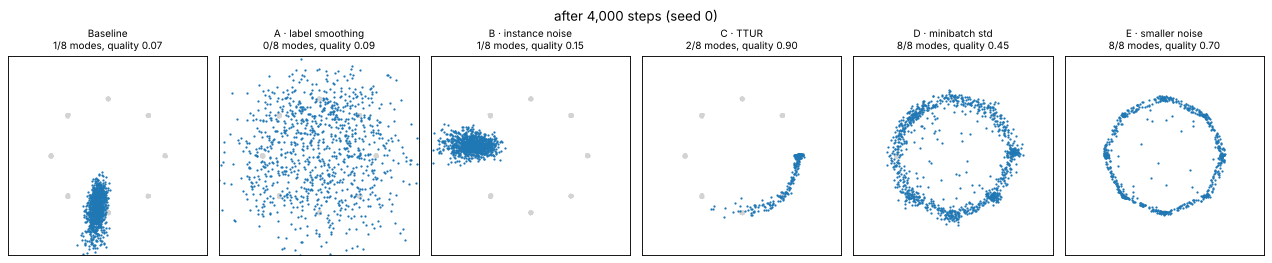

experiment                             final modes  best modes at any snapshot final quality
Baseline                                       1/8                         1/8          0.07
A · label smoothing (real_label=0.9)           0/8                         2/8          0.09
B · instance noise (0.3)                       1/8                         1/8          0.15
C · TTUR (lr_d=4e-4)                           2/8                         3/8          0.90
D · minibatch std (mbstd=True)                 8/8                         8/8          0.45
E · smaller noise (z_dim=2)                    8/8                         8/8          0.70


In [13]:
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
ref = sample_real(1000)
for a, (name, (losses, snaps)) in zip(axes, results.items()):
    step, pts, modes, quality = snaps[-1]
    a.scatter(*ref.T, s=1, c="lightgrey"); a.scatter(*pts.T, s=1, c="tab:blue")
    a.set_xlim(-3.5, 3.5); a.set_ylim(-3.5, 3.5); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{name.split(' (')[0]}\n{modes}/8 modes, quality {quality:.2f}", fontsize=9)
plt.suptitle("after 4,000 steps (seed 0)", y=1.02); plt.tight_layout(); plt.show()

print(f"{'experiment':38s} {'final modes':>11s} {'best modes at any snapshot':>27s} {'final quality':>13s}")
for name, (losses, snaps) in results.items():
    print(f"{name:38s} {snaps[-1][2]:>9d}/8 {max(s[2] for s in snaps):>25d}/8 {snaps[-1][3]:>13.2f}")

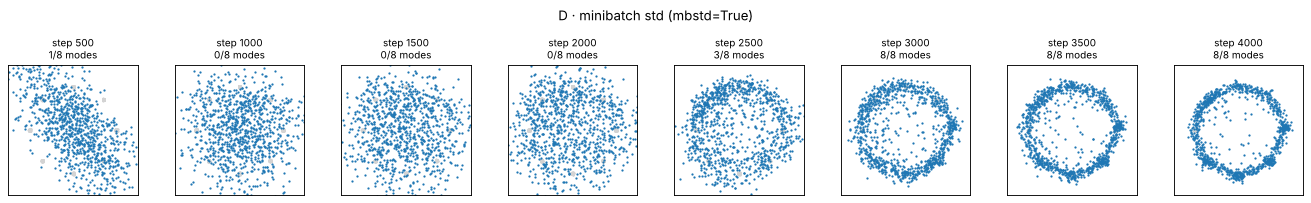

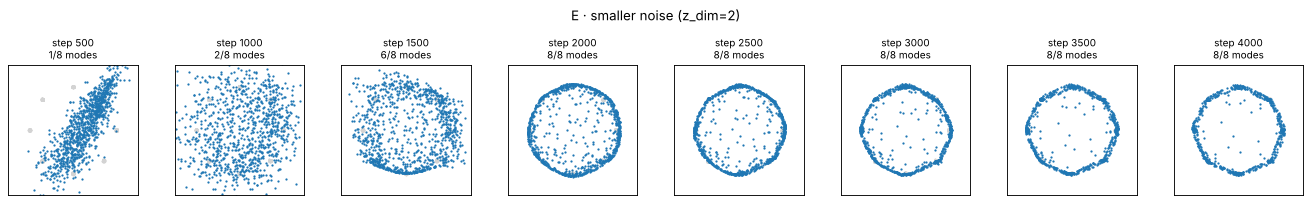

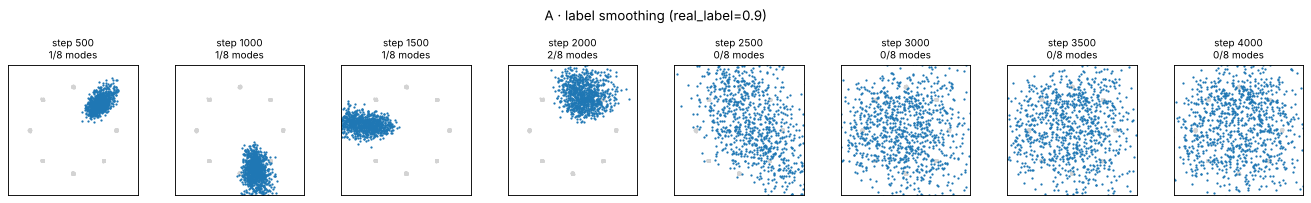

In [14]:
for name in ["D · minibatch std (mbstd=True)", "E · smaller noise (z_dim=2)", "A · label smoothing (real_label=0.9)"]:
    show_snapshots(results[name][1], name)

### Results table (filled in from this run, next to the course guide's run)

| Experiment | Change | Fixes collapse? | **This run** (seed 0): final modes, quality | Best modes at any snapshot | Course guide's run (seed 0) |
|---|---|---|---|---|---|
| Baseline | none | — | **1/8**, 0.07 | 1/8 | 1/8 |
| A · one-sided label smoothing | `real_label=0.9` | **no** (worse) | **0/8**, 0.09: points scattered all over, missing the clusters | 2/8 | 0/8, scattered |
| B · instance noise | `instance_noise=0.3` | **no** | **1/8**, 0.15: still one blob | 1/8 | 1/8, still one blob |
| C · TTUR | `lr_d=4e-4` | **no** (partly sharper) | **2/8**, 0.90: a sharp arc reaching one or two clusters | 3/8 | 1–2 of 8, sharper points |
| D · minibatch std | `mbstd=True` | **yes** | **8/8**, 0.45: a ring with all 8 clusters, many points still between them | 8/8 | 8/8 |
| E · smaller noise vector | `z_dim=2` | **yes** | **8/8**, 0.70: a thin ring | 8/8 | 8/8, as a thin ring |

Our run reproduces the guide's pattern **fix for fix**. The only differences are details: TTUR covered 2 (at best 3) clusters instead of 1–2, and minibatch std recovered all 8 clusters but with a lower quality score (0.45: about half the points lie on the "bridges" between clusters) than a perfect generator would get. Minibatch std needed time: it was at 0–3 modes until step 2,500, then jumped to 8/8 by step 3,000. Label smoothing briefly touched 2 clusters at step 2,000 before scattering.

**What the results teach.** - **Match the fix to the cause.** Collapse happens because D can't see variety. **Minibatch std gives D exactly that information**, and it recovered all 8 clusters.
- **A fix aimed at a different problem won't help.** Label smoothing and instance noise are designed to calm an *over-confident* D. They did not fix collapse here, and label smoothing even made the generator worse (0/8).
- **Better quality isn't better variety.** TTUR produced the sharpest points (quality 0.90) but still covered only 2 clusters.
- **Setup matters too.** With a 2-number noise vector, G stretched over the whole ring. It leaves points on the "bridges" between clusters because G is a smooth function of its input: it cannot jump from one cluster to the next without passing through the gap.

### Exercise 3 · Re-run the best setting with `seed=1`, then combine two fixes
One success can be luck. And the challenge: combine two fixes, for example `train_ring_gan(mbstd=True, lr_d=4e-4)`.

D · minibatch std, seed 1          modes per snapshot [1, 0, 0, 0, 3, 7, 8, 8]  final quality 0.47


E · z_dim=2, seed 1                modes per snapshot [2, 1, 2, 7, 8, 8, 8, 8]  final quality 0.67


challenge: mbstd + TTUR (seed 0)   modes per snapshot [0, 2, 4, 4, 5, 6, 6, 6]  final quality 0.34


challenge: mbstd + TTUR (seed 1)   modes per snapshot [0, 3, 4, 4, 5, 5, 7, 7]  final quality 0.33


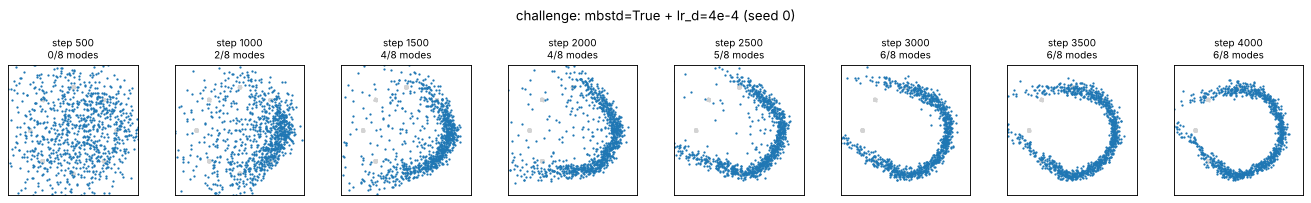

In [15]:
for name, kwargs in [("D · minibatch std, seed 1", dict(mbstd=True, seed=1)),
                     ("E · z_dim=2, seed 1", dict(z_dim=2, seed=1)),
                     ("challenge: mbstd + TTUR (seed 0)", dict(mbstd=True, lr_d=4e-4)),
                     ("challenge: mbstd + TTUR (seed 1)", dict(mbstd=True, lr_d=4e-4, seed=1))]:
    _, losses, snaps = train_ring_gan(**kwargs)
    results[name] = (losses, snaps)
    print(f"{name:34s} modes per snapshot {[s[2] for s in snaps]}  final quality {snaps[-1][3]:.2f}")
show_snapshots(results["challenge: mbstd + TTUR (seed 0)"][1], "challenge: mbstd=True + lr_d=4e-4 (seed 0)")

**Results (this run).**

| Run | modes per snapshot (every 500 steps) | final quality |
|---|---|---|
| D · minibatch std, **seed 1** | 1, 0, 0, 0, 3, 7, 8, **8** | 0.47 |
| E · z_dim = 2, **seed 1** | 2, 1, 2, 7, 8, 8, 8, **8** | 0.67 |
| challenge: mbstd + TTUR, seed 0 | 0, 2, 4, 4, 5, 6, 6, **6** | 0.34 |
| challenge: mbstd + TTUR, seed 1 | 0, 3, 4, 4, 5, 5, 7, **7** | 0.33 |

- Both successful fixes **also work with seed 1** (8/8), so their success was not luck.
- **Combining two fixes is not automatically better:** minibatch std + TTUR climbed towards full coverage *steadily* (no long collapsed phase), but ended at 6/8 and 7/8 with lower quality than minibatch std alone, within the same 4,000 steps. A D that learns 4× faster may push G around too hard for it to settle on every cluster. There is no single right answer here (the guide says the same); the point is to test, not assume.

## Part 5 · Diagnosing a real GAN on MNIST
Back to the **Class 1 MNIST GAN**: the same Generator (100 → 256 → 784, Tanh) and Discriminator (784 → 256 → 1, Sigmoid), same `BCELoss`, same Adam lr 0.0002. We add three diagnostic tools.

### 5.1 Loading MNIST (same as Class 1)

In [16]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
print(len(train_data), "training digits,", len(train_loader), "batches of 64 per epoch")


class Generator(nn.Module):              # Class 1, unchanged
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(100, 256), nn.ReLU(), nn.Linear(256, 784), nn.Tanh())
    def forward(self, x):
        return self.fc(x).view(-1, 1, 28, 28)


class Discriminator(nn.Module):          # Class 1, unchanged
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(784, 256), nn.LeakyReLU(0.2), nn.Linear(256, 1), nn.Sigmoid())
    def forward(self, x):
        return self.fc(x.view(-1, 784))

60000 training digits, 938 batches of 64 per epoch


### 5.2 Tool 1: a digit counter
An ordinary classifier trained for **one epoch**, used only as a measuring tool. `digit_histogram(G)` makes 1,000 fake digits, asks the classifier which digit each one is, and counts them. A healthy generator gives roughly 100 of each; a few very tall bars mean mode collapse. **Careful:** the classifier always answers *some* digit, even for noise, so read the counts together with the pictures.

In [17]:
torch.manual_seed(0)
classifier = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))
opt_c = optim.Adam(classifier.parameters(), lr=1e-3)
t0 = time.time()
for x, y in train_loader:
    opt_c.zero_grad(); nn.functional.cross_entropy(classifier(x), y).backward(); opt_c.step()
test_data = datasets.MNIST(root='./data', train=False, transform=transform, download=True)
with torch.no_grad():
    xt = (test_data.data.float() / 255 - 0.5) / 0.5            # same transform, applied to all test images at once
    acc = (classifier(xt).argmax(1) == test_data.targets).float().mean().item()
print(f"digit counter: test accuracy {acc:.1%} after 1 epoch ({time.time() - t0:.0f} s)")


def digit_histogram(G, n=1000, seed=123):
    torch.manual_seed(seed)
    with torch.no_grad():
        digits = classifier(G(torch.randn(n, 100))).argmax(1)
    return torch.bincount(digits, minlength=10).numpy()

digit counter: test accuracy 93.8% after 1 epoch (10 s)


### 5.3 Tools 2 and 3: training with diagnostics
`train_mnist_gan(epochs=3, betas=..., real_label=...)` is the Class 1 loop plus logging. Every 100 steps it records the two losses, **mean D(x)** (D's average belief that real images are real, `out_real.mean()`) and **mean D(G(z))** (D's average belief that fakes are real, `out_fake.mean()`). After each epoch it draws the **same 16 fixed noise vectors**, so the rows of the grid show pure learning, not new random inputs.

In [18]:
def train_mnist_gan(epochs=3, betas=(0.9, 0.999), real_label=1.0, seed=0, log_every=100):
    torch.manual_seed(seed)
    G, D = Generator(), Discriminator()
    criterion = nn.BCELoss()
    opt_g = optim.Adam(G.parameters(), lr=0.0002, betas=betas)
    opt_d = optim.Adam(D.parameters(), lr=0.0002, betas=betas)
    fixed_noise = torch.randn(16, 100)
    log = {"step": [], "loss_d": [], "loss_g": [], "d_real": [], "d_fake": []}
    grids, step, t0 = [], 0, time.time()
    for epoch in range(epochs):
        for real, _ in train_loader:
            b = real.size(0)
            # Step 1: D  (real -> real_label, fake -> 0)
            opt_d.zero_grad()
            out_real = D(real)
            fake = G(torch.randn(b, 100))
            out_fake = D(fake.detach())
            loss_d = criterion(out_real, torch.full((b, 1), real_label)) + criterion(out_fake, torch.zeros(b, 1))
            loss_d.backward(); opt_d.step()
            # Step 2: G  (non-saturating: fakes -> 1)
            opt_g.zero_grad()
            loss_g = criterion(D(fake), torch.ones(b, 1))
            loss_g.backward(); opt_g.step()
            if step % log_every == 0:
                log["step"].append(step); log["loss_d"].append(loss_d.item()); log["loss_g"].append(loss_g.item())
                log["d_real"].append(out_real.mean().item()); log["d_fake"].append(out_fake.mean().item())
            step += 1
        with torch.no_grad():
            grids.append(G(fixed_noise))
        print(f"epoch {epoch + 1}: loss D {loss_d.item():.3f}, loss G {loss_g.item():.3f}, "
              f"mean D(x) {out_real.mean().item():.3f}, mean D(G(z)) {out_fake.mean().item():.3f}  ({time.time() - t0:.0f} s)")
    return G, log, grids


def show_diagnostics(G, log, grids, title):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    ax[0].plot(log["step"], log["loss_d"], label="loss D"); ax[0].plot(log["step"], log["loss_g"], label="loss G")
    ax[0].axhline(1.386, ls="--", c="k", lw=1, label="1.386"); ax[0].axhline(0.693, ls=":", c="k", lw=1, label="0.693")
    ax[0].set_title("losses"); ax[0].set_xlabel("step"); ax[0].legend(fontsize=8)
    ax[1].plot(log["step"], log["d_real"], label="mean D(x)"); ax[1].plot(log["step"], log["d_fake"], label="mean D(G(z))")
    ax[1].axhline(0.5, ls=":", c="k", lw=1); ax[1].set_ylim(0, 1); ax[1].set_title("who is winning?"); ax[1].set_xlabel("step"); ax[1].legend(fontsize=8)
    counts = digit_histogram(G)
    ax[2].bar(range(10), counts); ax[2].axhline(100, ls="--", c="k", lw=1); ax[2].set_xticks(range(10))
    ax[2].set_title("which digits? (1,000 samples)"); ax[2].set_xlabel("digit")
    plt.suptitle(title, y=1.03); plt.tight_layout(); plt.show()
    fig, axes = plt.subplots(len(grids), 1, figsize=(16, 1.25 * len(grids)))
    for e, (a, g) in enumerate(zip(np.atleast_1d(axes), grids)):
        a.imshow(make_grid(g, nrow=16, normalize=True, value_range=(-1, 1), pad_value=1).permute(1, 2, 0)); a.axis("off")
        a.set_title(f"{title}: 16 fixed noise vectors after epoch {e + 1}", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()
    print(f"{title}: digit counts 0..9 = {counts.tolist()}")
    return counts

**How to read the three plots**

| Plot | What to look for |
|---|---|
| **Losses** | compare with the dashed line (1.386) and dotted line (0.693), the values when D outputs 0.5. Wobbling is normal; drifting far away and staying there can mean one player is winning completely |
| **Who is winning?** | D(x) near 1 and D(G(z)) near 0: D wins easily and G gets little signal. Both near 0.5: D is confused, which is good *only if* the images also look good |
| **Which digits?** | even bars mean variety; a few tall bars mean mode collapse |

### Run A vs Run B
- **Run A:** the Class 1 settings: Adam `betas=(0.9, 0.999)` (the PyTorch default).
- **Run B:** `betas=(0.5, 0.999)` (DCGAN paper) **plus** one-sided label smoothing `real_label=0.9`. Lower β1 = less momentum, so the optimiser reacts faster to its changing opponent instead of overshooting.

> ✏️ **Predict:** which run will look healthier after 3 epochs? Could you tell from the losses alone?

epoch 1: loss D 0.730, loss G 1.249, mean D(x) 0.758, mean D(G(z)) 0.345  (12 s)


epoch 2: loss D 1.040, loss G 1.017, mean D(x) 0.673, mean D(G(z)) 0.447  (24 s)


epoch 3: loss D 0.713, loss G 1.405, mean D(x) 0.756, mean D(G(z)) 0.315  (36 s)


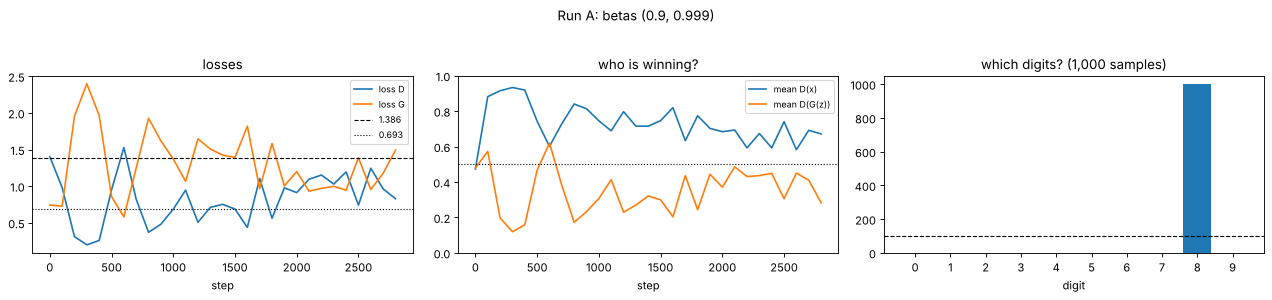

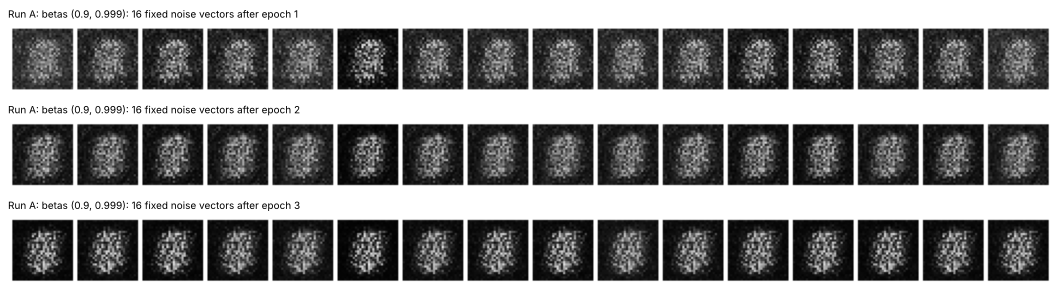

Run A: betas (0.9, 0.999): digit counts 0..9 = [0, 0, 0, 0, 0, 0, 0, 0, 1000, 0]


In [19]:
G_runA, log_A, grids_A = train_mnist_gan(epochs=3, betas=(0.9, 0.999), real_label=1.0)
counts_A = show_diagnostics(G_runA, log_A, grids_A, "Run A: betas (0.9, 0.999)")

epoch 1: loss D 1.051, loss G 1.154, mean D(x) 0.626, mean D(G(z)) 0.387  (12 s)


epoch 2: loss D 0.950, loss G 1.619, mean D(x) 0.660, mean D(G(z)) 0.327  (28 s)


epoch 3: loss D 0.975, loss G 1.302, mean D(x) 0.506, mean D(G(z)) 0.134  (44 s)


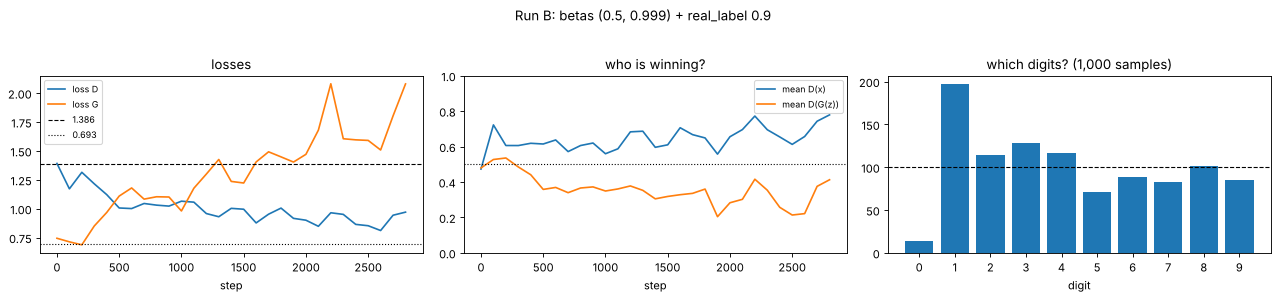

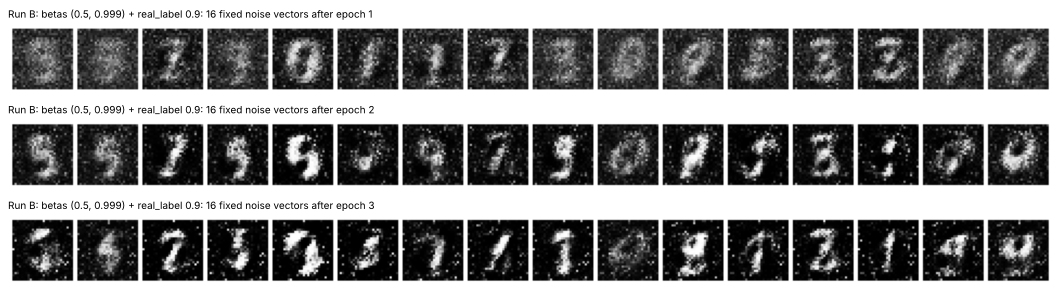

Run B: betas (0.5, 0.999) + real_label 0.9: digit counts 0..9 = [14, 197, 114, 128, 117, 71, 89, 83, 102, 85]


In [20]:
G_runB, log_B, grids_B = train_mnist_gan(epochs=3, betas=(0.5, 0.999), real_label=0.9)
counts_B = show_diagnostics(G_runB, log_B, grids_B, "Run B: betas (0.5, 0.999) + real_label 0.9")

In [21]:
for name, log, counts in [("Run A", log_A, counts_A), ("Run B", log_B, counts_B)]:
    last = slice(-10, None)        # the last 10 logged points (last ~1,000 steps)
    print(f"{name}: last 1,000 steps: mean loss D {np.mean(log['loss_d'][last]):.3f}, mean loss G {np.mean(log['loss_g'][last]):.3f}, "
          f"mean D(x) {np.mean(log['d_real'][last]):.3f}, mean D(G(z)) {np.mean(log['d_fake'][last]):.3f} | "
          f"digit counts min {counts.min()}, max {counts.max()}")

Run A: last 1,000 steps: mean loss D 1.013, mean loss G 1.105, mean D(x) 0.663, mean D(G(z)) 0.407 | digit counts min 0, max 1000
Run B: last 1,000 steps: mean loss D 0.903, mean loss G 1.682, mean D(x) 0.682, mean D(G(z)) 0.304 | digit counts min 14, max 197


**Answer revealed (this run).** | | Run A: β1 = 0.9 (Class 1 settings) | Run B: β1 = 0.5 + real_label 0.9 |
|---|---|---|
| **grids** | **collapsed**: after every epoch all 16 fixed-noise images are the **same** speckled blob | recognisable, **varied** digits (2, 3, 1, 7, 9 ...), improving from epoch 1 to 3 |
| **histogram** (1,000 samples) | **all 1,000 labelled "8"** | all ten digits, from **14** (digit 0) to **197** (digit 1) |
| **who is winning?** | D dominates early (D(x) ≈ 0.93, D(G(z)) ≈ 0.12 around step 300), a big swing near step 600, then zigzags; last 1,000 steps D(x) 0.66, D(G(z)) 0.41 | steadier: D(x) about 0.6–0.75, D(G(z)) slowly falling from 0.5 to about 0.2–0.4; last 1,000 steps D(x) 0.68, D(G(z)) 0.30 |
| **losses** (last 1,000 steps) | D 1.01, G 1.11 | D 0.90, G 1.68 |

This reproduces the guide's test run almost exactly: there too, Run A collapsed completely and "the digit counter labelled all 1,000 samples as 8", while Run B produced varied digits with counts spread over all ten digits (lowest about 30, highest about 160; ours: 14 and 197). The slides' description of Run A's D plot ("D dominates early, a big swing near step 600, then zigzags") matches ours too.

**Exercise 4 · model answers.**
1. *Which run is healthier, and what evidence?* **Run B**, clearly. Evidence: the grids (real, different digits vs one repeated blob), the histogram (ten digits vs one) and the D plot (steadier contest vs early domination and big swings).
2. *Could you have told the better run from the losses alone?* **No.** In the last 1,000 steps Run A's numbers actually look *more* "balanced" (losses 1.01 / 1.11, closer to 1.386 / 0.693; D(G(z)) 0.41, closer to 0.5) than Run B's (0.90 / 1.68; D(G(z)) 0.30). As the slides say, after step 1,000 A's numbers look "healthy" too. Yet A is the completely collapsed run. **The losses alone would have picked the wrong run.** That is the main lesson of the day. And the trap: Run A's histogram says "1,000 eights", but the grid shows no eights at all, only junk; the counter always answers *some* digit.
3. *A trap to notice:* the digit counter **always** answers some digit, even for noise. Read the histogram **together with** the grid.

## Part 6 · Wrap-up and reflection questions (model answers)

| Notebook part | What it demonstrated (this run) |
|---|---|
| 1 · x·y game | gradient play circles a Nash equilibrium; a smaller lr only slows it |
| 3 · ring baseline | mode collapse and hopping, invisible in the loss curve |
| 4 · five fixes | fixes work only on the problem they target; check with another seed |
| 5 · MNIST diagnostics | D scores, fixed-noise grids and digit counts show what losses hide |

1. **Explain Nash equilibrium using the x·y game.** At (0, 0), if y stays at 0, nothing x does changes V, so x can't gain by moving; the same holds for y when x is 0. Neither player can improve by changing alone, so (0, 0) is a Nash equilibrium. (For a GAN: p_g = p_data and D = ½ everywhere.)
2. **Why did simultaneous updates spiral out while alternating updates circled?** Simultaneous updates use the old values, so every step pushes the pair slightly further out, by a factor √(1 + lr²) (we measured 1.41 → 3.83 in 200 steps). With alternating updates the second player reacts to the first player's *new* position, which exactly cancels that growth, so the path stays on a loop. Neither aims at the equilibrium, because each gradient depends on the other player.
3. **Why can't a one-sample discriminator easily detect mode collapse?** It scores each sample on its own. A single realistic sample looks real whether or not every other sample is the same, so the loss gives no penalty for missing variety. (Minibatch std fixes exactly this by showing D a batch statistic.)
4. **Which diagnostic would you check first for mode collapse?** A grid of many samples, or a class histogram if a classifier is available. Losses and D scores can look normal during collapse; only looking at many outputs together shows the missing variety.

### Exit ticket (last slide) with answers
1. *Define Nash equilibrium. What is the GAN's equilibrium?* Nobody gains by changing alone; p_g = p_data and D = ½.
2. *Losses look calm, but 900 of 1,000 samples are the digit 1.* Mode collapse; minibatch std / minibatch discrimination.
3. *Mean D(x) ≈ 1.0 and D(G(z)) ≈ 0.0 for a long time.* D is too strong; G's gradients vanish and G stops learning.

### Common questions
- **If the equilibrium exists, why doesn't training find it?** The existence proof assumes unlimited capacity and a perfectly trained D at every step. Real training takes small alternating gradient steps with finite networks, and as Part 1 shows, those steps tend to circle the equilibrium.
- **Does a lower loss mean a better GAN?** No. Each loss depends on both players; G's loss can rise because D improved, even if G didn't change.
- **Label smoothing didn't fix collapse. Is it a bad trick?** No, it targets a different problem (an over-confident D). Choose the fix by the problem you see.
- **What is BCEWithLogitsLoss?** Sigmoid + BCE in one step: same result, no numerical problems with very confident scores. Part 5 keeps Class 1's Sigmoid + `BCELoss` so the code matches.
- **What is WGAN (mentioned in the slides)?** A redesigned GAN whose "critic" estimates a distance between the real and fake distributions instead of a probability, so it keeps giving useful gradients. Not part of this notebook, and not a guaranteed fix.

**Next:** `03_dcgan_and_conditional_gan.ipynb` (Class 4: convolutional G and D, and telling G which digit to draw).

*Source: reconstructed from the course guide "GAN Class 2 & 3 Notebook Explained" (GAN-Class-2-3-Training-Dynamics.ipynb) and the Class 2 & 3 slides. Papers: Goodfellow et al. 2014; Radford et al. 2015 (DCGAN); Salimans et al. 2016 (label smoothing, minibatch discrimination); Arjovsky and Bottou 2017 (instance noise); Heusel et al. 2017 (TTUR); Karras et al. 2018 (minibatch std).*